# 03 — Training monitoring and failure diagnosis (deliverable 2)

Two questions about the feed-forward network of notebook 02:

1. **Is the training itself working?** Two sanity checks: the initial loss, and overfitting a single batch.
2. **Why doesn't the network generalise, and what would fix it?** A learning-rate sweep, the overfitting of the large network at 128 px, and a learning curve.

Each experiment ends with **what we see / why / fix**. Setup from notebook 02: 32 px inputs, hidden layers 256 and 128, Adam, batches of 64. Everything is measured on the validation set.

In [1]:
import math
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset

sys.path.insert(0, "../src")
from museum.data import ROOT, get_loaders
from museum.diagnostics import dead_relu_fraction, overfit_one_batch
from museum.models import StyleMLP
from museum.train import evaluate, fit, get_device, predict, train_one_epoch

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: 1 seed and a few epochs, for a quick check
EPOCHS = 8 if FAST_RUN else 40
SEEDS = [0] if FAST_RUN else [0, 1, 2]
SIZE = 32            # chosen in notebook 02
HIDDEN = (256, 128)
BATCH_SIZE = 64

torch.manual_seed(0)
device = get_device()
loss_fn = nn.CrossEntropyLoss()
FIG_DIR = ROOT / "results" / "figures"
train_dl, val_dl, _, classes = get_loaders(img_size=SIZE, batch_size=BATCH_SIZE)
print("device:", device, "| FAST_RUN:", FAST_RUN, "| epochs:", EPOCHS, "| seeds:", SEEDS)

device: mps | FAST_RUN: False | epochs: 40 | seeds: [0, 1, 2]


## 1. Sanity check: the initial loss

Before any training, a network with no preference between 5 styles should give each a probability of 1/5, so a cross-entropy of ln 5 ≈ 1.609. Any other value points to a bug in the data, the labels or the initialisation.

In [2]:
torch.manual_seed(0)
model = StyleMLP(img_size=SIZE, hidden=HIDDEN).to(device)
initial_loss, initial_acc = evaluate(model, val_dl, loss_fn, device)
print(f"initial validation loss {initial_loss:.4f} (ln 5 = {math.log(5):.4f}), accuracy {initial_acc:.3f}")
assert abs(initial_loss - math.log(5)) < 0.05, "the initial loss should be ln 5"

initial validation loss 1.6098 (ln 5 = 1.6094), accuracy 0.156


**What we see.** Initial loss 1.610 vs ln 5 = 1.609: the data, the labels and the initialisation are consistent.

## 2. Sanity check: overfitting one batch

The network should be able to memorise 32 images: if it can't drive the loss on one fixed batch to almost 0, something is broken (the loss, the labels, the optimiser, the gradients), and no amount of data or tuning will help.

loss: step 1 1.598, step 300 0.00000; below 0.05 from step 7


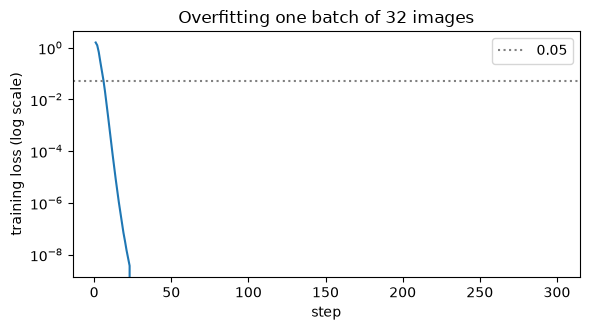

In [3]:
xb, yb = next(iter(DataLoader(train_dl.dataset, batch_size=32)))   # the same 32 images at every step
xb, yb = xb.to(device), yb.to(device)
torch.manual_seed(0)
model = StyleMLP(img_size=SIZE, hidden=HIDDEN).to(device)
losses = overfit_one_batch(model, xb, yb, torch.optim.Adam(model.parameters(), lr=1e-3), steps=300)
first_below = next(i for i, loss in enumerate(losses) if loss < 0.05) + 1
print(f"loss: step 1 {losses[0]:.3f}, step 300 {losses[-1]:.5f}; below 0.05 from step {first_below}")
assert losses[-1] < 0.05, "one batch should be overfitted"

fig, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(range(1, len(losses) + 1), losses)
ax.axhline(0.05, color="grey", ls=":", label="0.05")
ax.set(yscale="log", xlabel="step", ylabel="training loss (log scale)", title="Overfitting one batch of 32 images")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_one_batch.png", dpi=150, bbox_inches="tight")
plt.show()

**What we see.** The loss on the fixed batch falls below 0.05 by step 7 and reaches about 0 by step 300.

**Why it matters.** The network, the loss and the optimiser work together. From here on, every failure is about **generalisation**, not a bug.

## 3. Learning-rate sweep

Adam at five learning rates, 3 seeds each. After training we also measure the share of **dead ReLU units**: units that output 0 for every validation image, so they no longer pass any gradient.

**Rule, fixed before looking at the results:** keep the learning rate with the highest mean best validation accuracy. It is used for the rest of the FFN work (ablation A7).

chosen learning rate: 0.0001


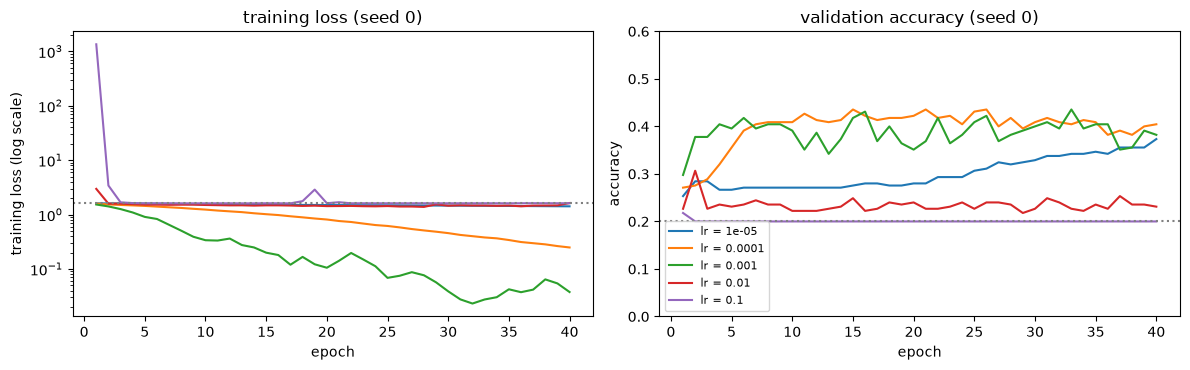

,best val acc (mean),best val acc (std),lowest val loss (mean),lowest val loss (std),final train loss (mean),final train loss (std),"dead ReLUs, layer 1 (mean)","dead ReLUs, layer 1 (std)","dead ReLUs, layer 2 (mean)","dead ReLUs, layer 2 (std)"
lr,,,,,,,,,,
0.00001,0.357,0.014,1.475,0.004,1.415,0.003,0.0,0.0,0.000,0.000
0.00010,0.440,0.008,1.408,0.005,0.263,0.015,0.0,0.0,0.000,0.000
0.00100,0.430,0.007,1.462,0.017,0.056,0.025,0.0,0.0,0.003,0.005
0.01000,0.293,0.027,1.555,0.024,1.524,0.126,0.0,0.0,0.961,0.028
0.10000,0.206,0.010,1.649,0.069,1.615,0.002,0.0,0.0,0.995,0.009


In [4]:
LRS = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
x_val = torch.cat([x for x, _ in val_dl]).to(device)
rows, curves = [], {}
for lr in LRS:
    for seed in SEEDS:
        train_dl, val_dl, _, _ = get_loaders(img_size=SIZE, batch_size=BATCH_SIZE, seed=seed)
        torch.manual_seed(seed)
        model = StyleMLP(img_size=SIZE, hidden=HIDDEN)
        h = fit(model, train_dl, val_dl, loss_fn, torch.optim.Adam(model.parameters(), lr=lr), EPOCHS, device,
                verbose=False)
        if seed == SEEDS[0]:
            curves[lr] = h
        rows.append({"lr": lr, "seed": seed, "best val acc": max(h["val_acc"]), "lowest val loss": min(h["val_loss"]),
                     "final train loss": h["train_loss"][-1],
                     "dead ReLUs, layer 1": dead_relu_fraction(model, x_val)[0],
                     "dead ReLUs, layer 2": dead_relu_fraction(model, x_val)[1]})
sweep = pd.DataFrame(rows).groupby("lr").agg(["mean", "std"]).drop(columns="seed")
sweep.columns = [f"{metric} ({stat})" for metric, stat in sweep.columns]
LR = float(sweep["best val acc (mean)"].idxmax())
print(f"chosen learning rate: {LR:g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for lr, h in curves.items():
    epochs = range(1, len(h["train_loss"]) + 1)
    axes[0].plot(epochs, h["train_loss"], label=f"lr = {lr:g}")
    axes[1].plot(epochs, h["val_acc"], label=f"lr = {lr:g}")
axes[0].axhline(math.log(5), color="grey", ls=":")
axes[1].axhline(0.2, color="grey", ls=":")
axes[0].set(yscale="log", xlabel="epoch", ylabel="training loss (log scale)", title="training loss (seed 0)")
axes[1].set(xlabel="epoch", ylabel="accuracy", ylim=(0, 0.6), title="validation accuracy (seed 0)")
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "03_lr_sweep.png", dpi=150, bbox_inches="tight")
plt.show()
sweep.round(3)

**What we see** (Adam, 32 px, 40 epochs, 3 seeds):

| Learning rate | Behaviour | Best val acc |
|---|---|---|
| 1e-5 | too slow: after 40 epochs the training loss is still 1.42, barely below ln 5 | 0.357 |
| **1e-4** | smooth: the training loss falls steadily to 0.26; also the lowest validation loss (1.408) | **0.440 ± 0.008** |
| 1e-3 | fast but noisy: the training loss reaches 0.06 (memorised), and validation accuracy jumps around | 0.430 ± 0.007 |
| 1e-2 | broken: the training loss is stuck around 1.5; **96 %** of the second-layer ReLUs are dead | 0.293 |
| 1e-1 | diverges, then dies: the first epoch's loss reaches ~1,000, then **99.5 %** of the second-layer ReLUs are dead and the accuracy is chance | 0.206 |

**Why.**
- **Step size.** Too small a step barely moves the weights; too large a step overshoots.
- **Dead ReLUs.** With ReLU, one large update can push a unit's input below 0 for every image. The unit then outputs 0, receives no gradient, and never recovers: a **dead ReLU**.
- **A dead layer.** When almost the whole second layer is dead, the output layer receives zeros and predicts the same thing for every image, so the loss stays near ln 5 and the accuracy at chance.

**Fix.** Learning rate **1e-4** (rule above), used in the ablation (A7). 1e-3, used in notebook 02, is close in accuracy but memorises faster and is noisier.

## 4. Why doesn't it generalise? The large network at 128 px

The 128 px network has 12.6 M parameters for 1,050 training images. We train it with the chosen learning rate and record, at every epoch, the losses and accuracies and the network's **confidence** (its highest softmax probability) on the validation images it gets right and on those it gets wrong.

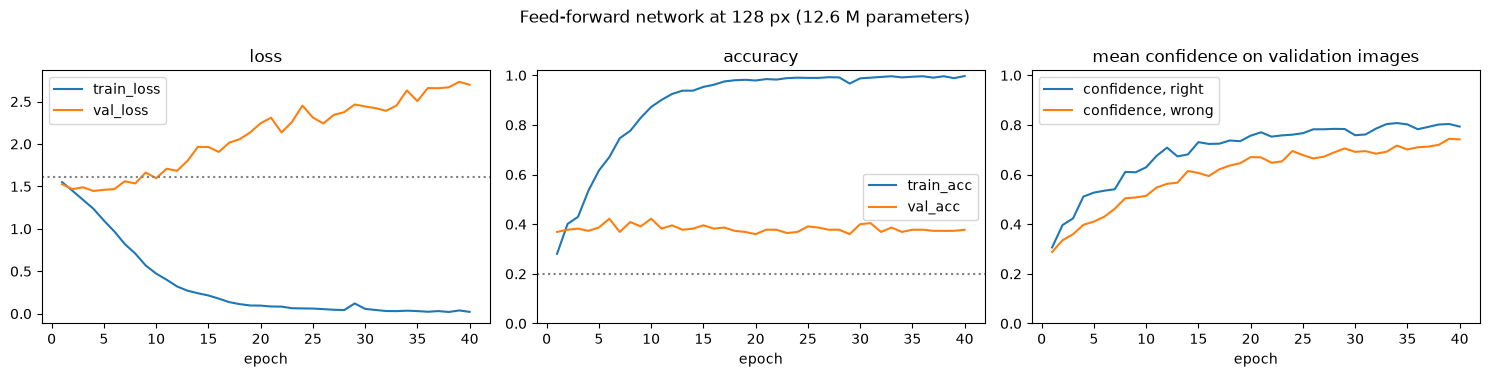

lowest validation loss at epoch 4: 1.446, val acc 0.373


,train_loss,val_loss,train_acc,val_acc,"confidence, right","confidence, wrong"
epoch,,,,,,
1,1.550,1.526,0.281,0.369,0.306,0.288
4,1.236,1.446,0.535,0.373,0.512,0.398
21,0.085,2.309,0.985,0.378,0.770,0.669
40,0.021,2.698,0.997,0.378,0.793,0.742


In [5]:
train_dl, val_dl, _, _ = get_loaders(img_size=128, batch_size=BATCH_SIZE, seed=0)
torch.manual_seed(0)
model = StyleMLP(img_size=128, hidden=HIDDEN).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
log = []
for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc, _ = train_one_epoch(model, train_dl, loss_fn, optimizer, device)
    val_loss, _ = evaluate(model, val_dl, loss_fn, device)
    y_true, y_pred, probs = predict(model, val_dl, device)
    right, confidence = y_true == y_pred, probs.max(axis=1)
    log.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "train_acc": train_acc,
                "val_acc": right.mean(), "confidence, right": confidence[right].mean(),
                "confidence, wrong": confidence[~right].mean()})
log = pd.DataFrame(log).set_index("epoch")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
log[["train_loss", "val_loss"]].plot(ax=axes[0], title="loss")
log[["train_acc", "val_acc"]].plot(ax=axes[1], title="accuracy", ylim=(0, 1.02))
log[["confidence, right", "confidence, wrong"]].plot(ax=axes[2], ylim=(0, 1.02),
                                                     title="mean confidence on validation images")
axes[0].axhline(math.log(5), color="grey", ls=":")
axes[1].axhline(0.2, color="grey", ls=":")
fig.suptitle("Feed-forward network at 128 px (12.6 M parameters)")
fig.tight_layout()
fig.savefig(FIG_DIR / "03_overfitting_128px.png", dpi=150, bbox_inches="tight")
plt.show()

best = log["val_loss"].idxmin()
print(f"lowest validation loss at epoch {best}: {log.loc[best, 'val_loss']:.3f}, val acc {log.loc[best, 'val_acc']:.3f}")
log.iloc[[0, best - 1, len(log) // 2, -1]].round(3)

**What we see.**
- **Training:** the loss goes from 1.55 to 0.02 and the accuracy from 0.28 to 0.997. The network memorises the 1,050 images.
- **Validation:** the loss is lowest at epoch 4 (1.446, accuracy 0.373), then climbs to 2.70, while the accuracy stays flat between 0.36 and 0.42.
- **Confidence:** on the validation images it gets wrong, the mean confidence rises from 0.29 to 0.74, almost as high as on those it gets right (0.79).

**Why.** This is **overfitting** (high variance). With far more parameters than examples, the network fits details of individual training images (exact pixel values at exact positions) that don't carry over to new paintings. Its confidence grows on every image, right or wrong. That's why the validation loss rises while the accuracy doesn't move: cross-entropy punishes confident mistakes heavily.

**Consequence for the guide.** The network is barely more confident when right than when wrong, so the confidence of an unregularised FFN is a poor signal for the guide's "not sure" answer (A10).

**Fixes**, tested in the ablation (A7):
- fewer parameters per image (a smaller input: already 32 px)
- dropout
- weight decay
- augmentation
- early stopping on the validation loss (here it would stop at epoch 4)

## 5. Would more data help? Learning curve at 32 px

Same network, trained on 25 %, 50 %, 75 % and 100 % of the training images (stratified, 3 seeds), always evaluated on the full validation set. If validation accuracy is still rising at 100 %, the network is limited by the amount of data (high variance), not by its capacity.

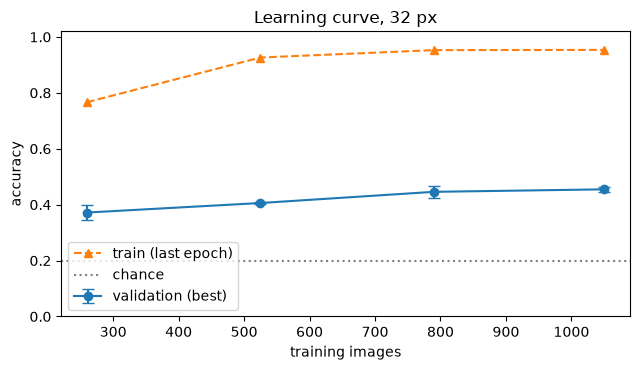

,best val acc (mean),best val acc (std),final train acc (mean),final train acc (std)
training images,,,,
260,0.372,0.026,0.767,0.055
525,0.406,0.005,0.926,0.012
790,0.446,0.021,0.953,0.010
1050,0.455,0.009,0.954,0.002


In [6]:
train_dl, val_dl, _, _ = get_loaders(img_size=SIZE, batch_size=BATCH_SIZE)
labels = train_dl.dataset.labels.numpy()
FRACTIONS = [0.25, 0.5, 0.75, 1.0]
rows = []
for fraction in FRACTIONS:
    for seed in SEEDS:
        rng = np.random.default_rng(seed)
        idx = np.concatenate([rng.permutation(np.flatnonzero(labels == c))[: round(fraction * 210)] for c in range(5)])
        subset_dl = DataLoader(Subset(train_dl.dataset, idx), batch_size=BATCH_SIZE, shuffle=True,
                               generator=torch.Generator().manual_seed(seed))
        torch.manual_seed(seed)
        model = StyleMLP(img_size=SIZE, hidden=HIDDEN)
        h = fit(model, subset_dl, val_dl, loss_fn, torch.optim.Adam(model.parameters(), lr=LR), EPOCHS, device,
                verbose=False)
        rows.append({"training images": len(idx), "seed": seed, "best val acc": max(h["val_acc"]),
                     "final train acc": h["train_acc"][-1]})
curve = pd.DataFrame(rows).groupby("training images").agg(["mean", "std"]).drop(columns="seed")
curve.columns = [f"{metric} ({stat})" for metric, stat in curve.columns]

fig, ax = plt.subplots(figsize=(6.5, 3.8))
ax.errorbar(curve.index, curve["best val acc (mean)"], yerr=curve["best val acc (std)"].fillna(0), marker="o",
            capsize=4, label="validation (best)")
ax.plot(curve.index, curve["final train acc (mean)"], marker="^", ls="--", label="train (last epoch)")
ax.axhline(0.2, color="grey", ls=":", label="chance")
ax.set(xlabel="training images", ylabel="accuracy", ylim=(0, 1.02), title="Learning curve, 32 px")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "03_learning_curve.png", dpi=150, bbox_inches="tight")
plt.show()
curve.round(3)

**What we see.**
- **Validation accuracy rises with more training images, but the gains shrink:** 0.372 (260 images) → 0.406 (525) → 0.446 (790) → 0.455 (1,050).
- **Training accuracy is high everywhere** (0.77–0.95). With a fixed 40 epochs, small subsets also get fewer updates, which is why their training accuracy is lower.
- **The 100 % point is noise-sensitive.** It gives 0.455, against 0.440 for the same setting in the sweep; the two runs differ only in the order of the batches. Differences of 1–2 points are within run-to-run noise.

**Why.** A large gap between training and validation that narrows as data is added is the signature of **high variance**: more data helps. But the curve is flattening around 45 %, so more images of the same kind would not bring an FFN anywhere near the 85 % target.

**Fix.**
- **Make the data go further and constrain the network:** we can't add data, but augmentation makes the images we have go further, and dropout and weight decay constrain the network (the ablation, A7).
- **Change the model:** the bigger fix is a model that doesn't have to learn every pixel position separately, a CNN (Antoine's ResNet, N3 and N4).

## Summary: the diagnosis

| Symptom | Evidence | Cause | Fix |
|---|---|---|---|
| (sanity checks pass) | initial loss 1.610 ≈ ln 5; one batch overfitted in 7 steps | the pipeline works | none needed |
| Training stuck at ln 5 for lr ≥ 1e-2 | 96–99.5 % of second-layer ReLUs dead | steps too large kill ReLU units | lr = 1e-4 |
| Train acc ~100 %, val acc ~40 %, val loss rising | 128 px: confidence on wrong answers 0.29 → 0.74 | overfitting: 12.6 M parameters for 1,050 images | smaller input (32 px), dropout, weight decay, augmentation, early stopping |
| More data helps, but less and less | learning curve 0.37 → 0.46, flattening | high variance, and no spatial structure in an FFN | regularisation (A7); a CNN (N3, N4) |

**Next: the ablation (A7).** The fixes are added one at a time, cumulatively, at 32 px and lr = 1e-4 with 3 seeds: baseline → dropout → weight decay → augmentation → early stopping.